<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Bubble Plots**


Estimated time needed: **30** minutes


In this lab, you will focus on visualizing data.

The dataset will be directly loaded into pandas for analysis and visualization.

You will use various visualization techniques to explore the data and uncover key trends.


## Objectives


In this lab, you will perform the following:


-   Visualize the distribution of data.

-   Visualize the relationship between two data features.

-   Visualize composition of data.

-   Visualize comparison of data.


#### Setup: Working with the Database
**Install and import the needed libraries**


In [1]:
!pip install pandas 
!pip install matplotlib

import pandas as pd
import matplotlib.pyplot as plt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 152.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 170.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pandas]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 166.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 165.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 105.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 170.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]


**Download and connect to the database file containing survey data.**


To start, download and load the dataset into a `pandas` DataFrame.



In [2]:
# Step 1: Download the dataset
!wget -O survey-data.csv https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv

# Load the data
df = pd.read_csv("survey-data.csv")

# Display the first few rows of the data to understand its structure
df.head()


Resolving cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)... 169.63.118.104
Connecting to cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)|169.63.118.104|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 159525875 (152M) [text/csv]
Saving to: ‘survey-data.csv’

survey-data.csv     100%[===================>] 152.13M  6.33MB/s    in 29s     

2026-08-21 12:35:45 (5.21 MB/s) - ‘survey-data.csv’ saved [159525875/159525875]


,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


### Task 1: Exploring Data Distributions Using Bubble Plots


#### 1. Bubble Plot for Age vs. Frequency of Participation


- Visualize the relationship between respondents’ age and their participation frequency (`SOPartFreq`) using a bubble plot.

- Use the size of the bubbles to represent their job satisfaction (`JobSat`).


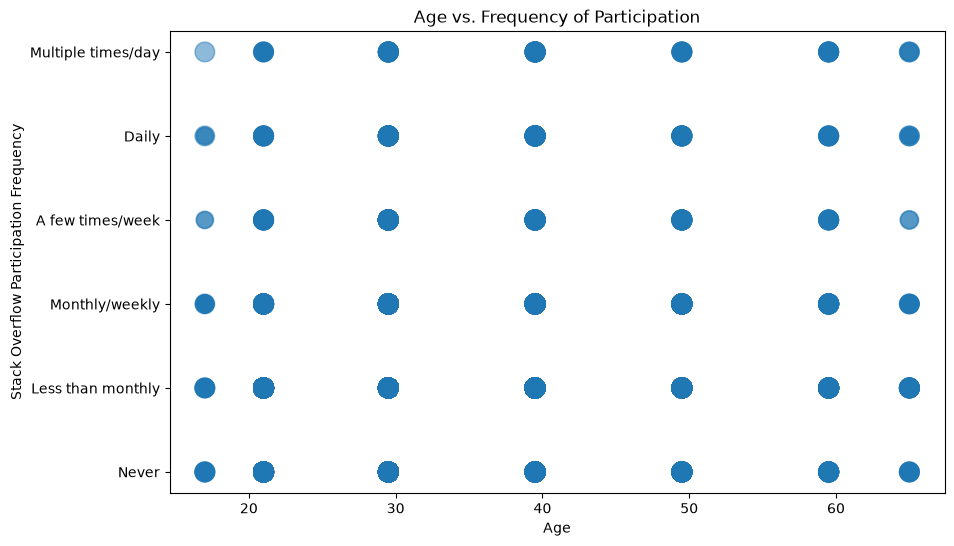

In [5]:
##Write your code here

# Convert Age groups to numeric values
age_mapping = {
    "Under 18 years old": 17,
    "18-24 years old": 21,
    "25-34 years old": 29.5,
    "35-44 years old": 39.5,
    "45-54 years old": 49.5,
    "55-64 years old": 59.5,
    "65 years or older": 65
}

age_numeric = df["Age"].map(age_mapping)

# Convert SOPartFreq categories to numeric values
freq_mapping = {
    "I have never participated in Q&A on Stack Overflow": 0,
    "Less than once per month or monthly": 1,
    "A few times per month or weekly": 2,
    "A few times per week": 3,
    "Daily or almost daily": 4,
    "Multiple times per day": 5
}

freq_numeric = df["SOPartFreq"].map(freq_mapping)

# Convert JobSat to numeric
jobsat_numeric = pd.to_numeric(df["JobSat"], errors="coerce")

# Create plotting DataFrame
plot_data = pd.DataFrame({
    "Age": age_numeric,
    "Frequency": freq_numeric,
    "JobSat": jobsat_numeric
}).dropna()

# Create bubble plot
plt.figure(figsize=(10, 6))

plt.scatter(
    plot_data["Age"],
    plot_data["Frequency"],
    s=plot_data["JobSat"] * 20,
    alpha=0.5
)

plt.title("Age vs. Frequency of Participation")
plt.xlabel("Age")
plt.ylabel("Stack Overflow Participation Frequency")

plt.yticks(
    [0, 1, 2, 3, 4, 5],
    [
        "Never",
        "Less than monthly",
        "Monthly/weekly",
        "A few times/week",
        "Daily",
        "Multiple times/day"
    ]
)

plt.show()

In [4]:
df["SOPartFreq"].value_counts(dropna=False)

SOPartFreq
Less than once per month or monthly                   24162
NaN                                                   20200
I have never participated in Q&A on Stack Overflow    11143
A few times per month or weekly                        6277
A few times per week                                   2278
Daily or almost daily                                   936
Multiple times per day                                  441
Name: count, dtype: int64

#### 2. Bubble Plot for Compensation vs. Job Satisfaction


-Visualize the relationship between yearly compensation (`ConvertedCompYearly`) and job satisfaction (`JobSat`).

- Use the size of the bubbles to represent respondents’ age.


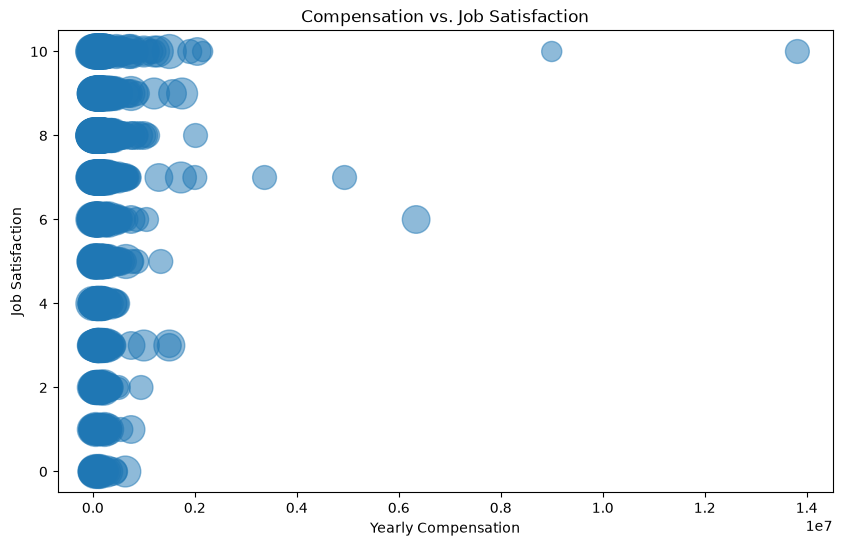

In [6]:
##Write your code here
# Convert Age groups to numeric values
age_mapping = {
    "Under 18 years old": 17,
    "18-24 years old": 21,
    "25-34 years old": 29.5,
    "35-44 years old": 39.5,
    "45-54 years old": 49.5,
    "55-64 years old": 59.5,
    "65 years or older": 65
}

age_numeric = df["Age"].map(age_mapping)

# Convert JobSat to numeric
jobsat_numeric = pd.to_numeric(df["JobSat"], errors="coerce")

# Convert compensation to numeric
comp_numeric = pd.to_numeric(
    df["ConvertedCompYearly"],
    errors="coerce"
)

# Create plotting data
plot_data = pd.DataFrame({
    "Compensation": comp_numeric,
    "JobSat": jobsat_numeric,
    "Age": age_numeric
}).dropna()

# Create bubble plot
plt.figure(figsize=(10, 6))

plt.scatter(
    plot_data["Compensation"],
    plot_data["JobSat"],
    s=plot_data["Age"] * 10,
    alpha=0.5
)

plt.title("Compensation vs. Job Satisfaction")
plt.xlabel("Yearly Compensation")
plt.ylabel("Job Satisfaction")

plt.show()

### Task 2: Analyzing Relationships Using Bubble Plots


#### 1. Bubble Plot of Technology Preferences by Age

- Visualize the popularity of programming languages respondents have worked with (`LanguageHaveWorkedWith`) across age groups.

- Use bubble size to represent the frequency of each language.



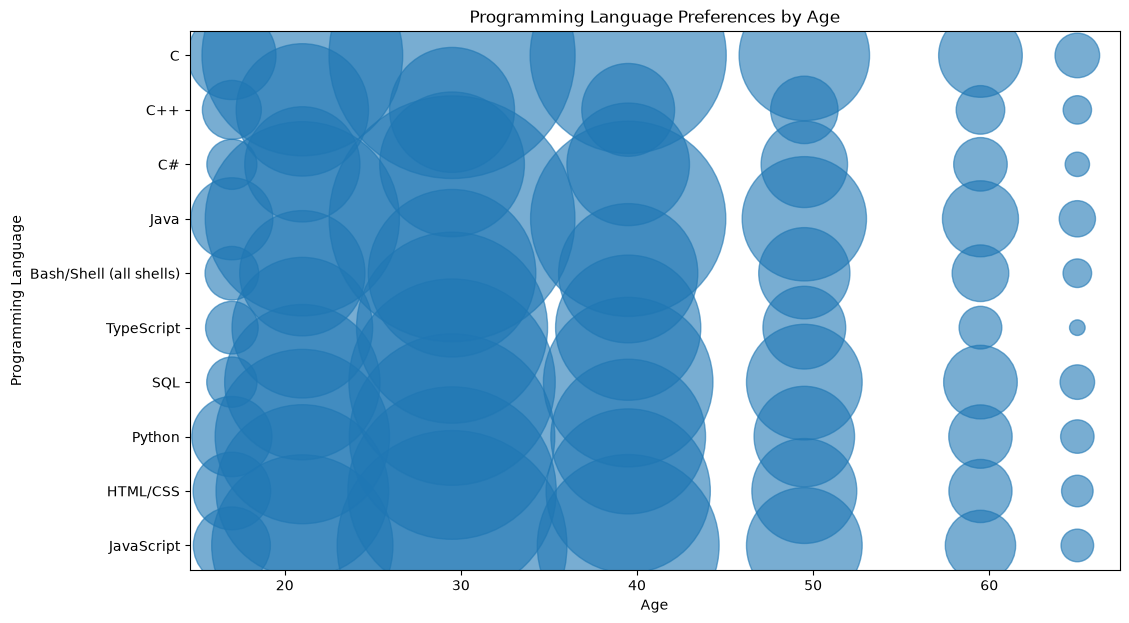

In [8]:
##Write your code here
# Convert Age groups to numeric values
age_mapping = {
    "Under 18 years old": 17,
    "18-24 years old": 21,
    "25-34 years old": 29.5,
    "35-44 years old": 39.5,
    "45-54 years old": 49.5,
    "55-64 years old": 59.5,
    "65 years or older": 65
}

age_numeric = df["Age"].map(age_mapping)

# Get the most common programming languages
languages = df["LanguageHaveWorkedWith"].dropna().str.split(";").explode()

top_languages = languages.value_counts().head(10).index

# Create bubble data
bubble_data = []

for language in top_languages:
    mask = df["LanguageHaveWorkedWith"].fillna("").str.contains(
        language, regex=False
    )

    for age in age_mapping:
        count = mask & (df["Age"] == age)

        bubble_data.append({
            "Language": language,
            "Age": age_mapping[age],
            "Frequency": count.sum()
        })

bubble_df = pd.DataFrame(bubble_data)

# Remove zero-frequency combinations
bubble_df = bubble_df[bubble_df["Frequency"] > 0]

# Create bubble plot
plt.figure(figsize=(12, 7))

plt.scatter(
    bubble_df["Age"],
    bubble_df["Language"],
    s=bubble_df["Frequency"] * 2,
    alpha=0.6
)

plt.title("Programming Language Preferences by Age")
plt.xlabel("Age")
plt.ylabel("Programming Language")

plt.show()

#### 2. Bubble Plot for Preferred Databases vs. Job Satisfaction

- Explore the relationship between preferred databases (`DatabaseWantToWorkWith`) and job satisfaction.

- Use bubble size to indicate the number of respondents for each database.


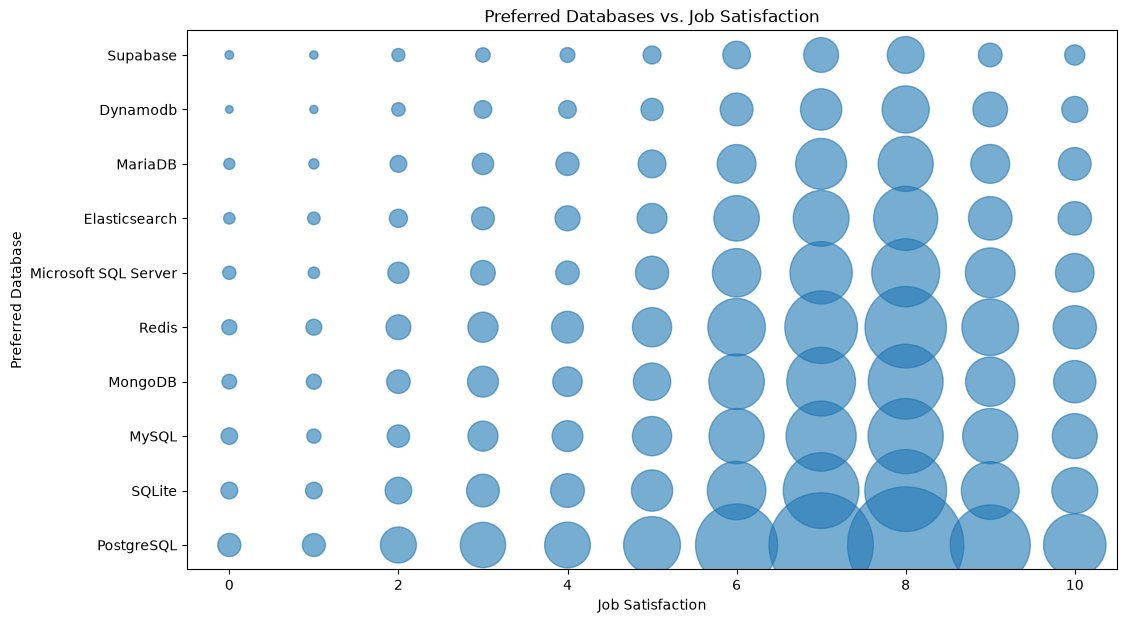

In [9]:
##Write your code here
# Get the most common databases
databases = df["DatabaseWantToWorkWith"].dropna().str.split(";").explode()

top_databases = databases.value_counts().head(10).index

# Create bubble data
bubble_data = []

for database in top_databases:
    mask = df["DatabaseWantToWorkWith"].fillna("").str.contains(
        database, regex=False
    )

    jobsat = pd.to_numeric(df["JobSat"], errors="coerce")

    for sat in sorted(jobsat.dropna().unique()):
        count = mask & (jobsat == sat)

        bubble_data.append({
            "Database": database,
            "JobSat": sat,
            "Frequency": count.sum()
        })

bubble_df = pd.DataFrame(bubble_data)

# Remove zero-frequency combinations
bubble_df = bubble_df[bubble_df["Frequency"] > 0]

# Bubble plot
plt.figure(figsize=(12, 7))

plt.scatter(
    bubble_df["JobSat"],
    bubble_df["Database"],
    s=bubble_df["Frequency"] * 2,
    alpha=0.6
)

plt.title("Preferred Databases vs. Job Satisfaction")
plt.xlabel("Job Satisfaction")
plt.ylabel("Preferred Database")

plt.show()

### Task 3: Comparing Data Using Bubble Plots


#### 1. Bubble Plot for Compensation Across Developer Roles

- Visualize compensation (`ConvertedCompYearly`) across different developer roles (`DevType`).

- Use bubble size to represent job satisfaction.


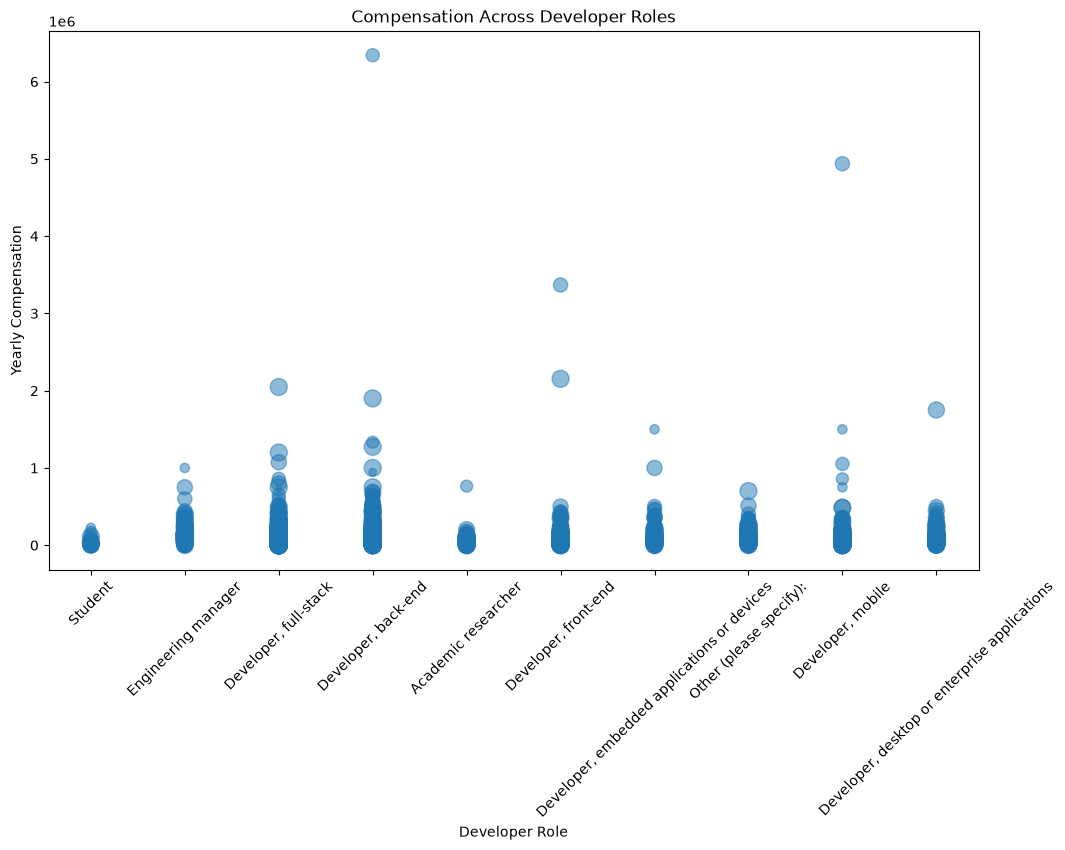

In [10]:
##Write your code here
# Get the top 10 developer roles
top_roles = df["DevType"].dropna().value_counts().head(10).index

# Keep only the top roles
role_data = df[df["DevType"].isin(top_roles)].copy()

# Convert compensation and job satisfaction to numeric
role_data["Compensation"] = pd.to_numeric(
    role_data["ConvertedCompYearly"],
    errors="coerce"
)

role_data["JobSat_num"] = pd.to_numeric(
    role_data["JobSat"],
    errors="coerce"
)

# Remove missing values
role_data = role_data.dropna(
    subset=["Compensation", "JobSat_num", "DevType"]
)

# Bubble plot
plt.figure(figsize=(12, 7))

plt.scatter(
    role_data["DevType"],
    role_data["Compensation"],
    s=role_data["JobSat_num"] * 15,
    alpha=0.5
)

plt.title("Compensation Across Developer Roles")
plt.xlabel("Developer Role")
plt.ylabel("Yearly Compensation")
plt.xticks(rotation=45)

plt.show()

#### 2. Bubble Plot for Collaboration Tools by Age

- Visualize the relationship between the collaboration tools used (`NEWCollabToolsHaveWorkedWith`) and age groups.

- Use bubble size to represent the frequency of tool usage.


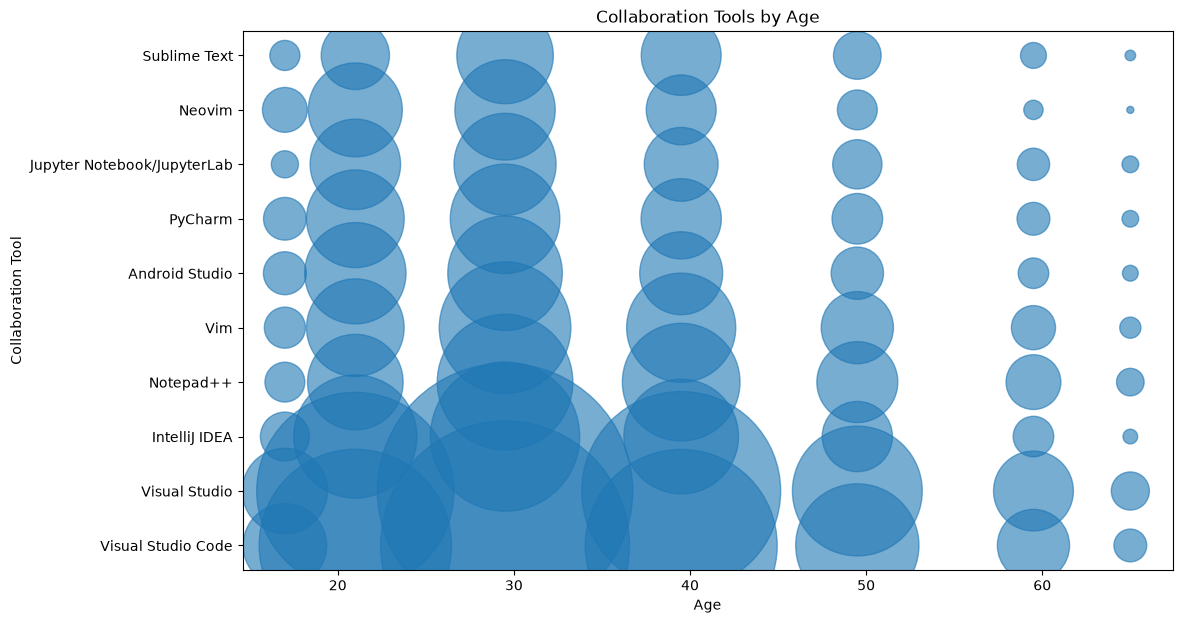

In [11]:
##Write your code here
# Convert Age groups to numeric values
age_mapping = {
    "Under 18 years old": 17,
    "18-24 years old": 21,
    "25-34 years old": 29.5,
    "35-44 years old": 39.5,
    "45-54 years old": 49.5,
    "55-64 years old": 59.5,
    "65 years or older": 65
}

# Get top collaboration tools
tools = (
    df["NEWCollabToolsHaveWorkedWith"]
    .dropna()
    .str.split(";")
    .explode()
)

top_tools = tools.value_counts().head(10).index

# Create bubble data
bubble_data = []

for tool in top_tools:
    mask = df["NEWCollabToolsHaveWorkedWith"].fillna("").str.contains(
        tool, regex=False
    )

    for age_group, age_value in age_mapping.items():
        count = mask & (df["Age"] == age_group)

        bubble_data.append({
            "Tool": tool,
            "Age": age_value,
            "Frequency": count.sum()
        })

bubble_df = pd.DataFrame(bubble_data)

# Remove zero-frequency combinations
bubble_df = bubble_df[bubble_df["Frequency"] > 0]

# Create bubble plot
plt.figure(figsize=(12, 7))

plt.scatter(
    bubble_df["Age"],
    bubble_df["Tool"],
    s=bubble_df["Frequency"] * 2,
    alpha=0.6
)

plt.title("Collaboration Tools by Age")
plt.xlabel("Age")
plt.ylabel("Collaboration Tool")

plt.show()

### Task 4: Visualizing Technology Trends Using Bubble Plots


#### 1. Bubble Plot for Preferred Web Frameworks vs. Job Satisfaction

- Explore the relationship between preferred web frameworks (`WebframeWantToWorkWith`) and job satisfaction.

- Use bubble size to represent the number of respondents.



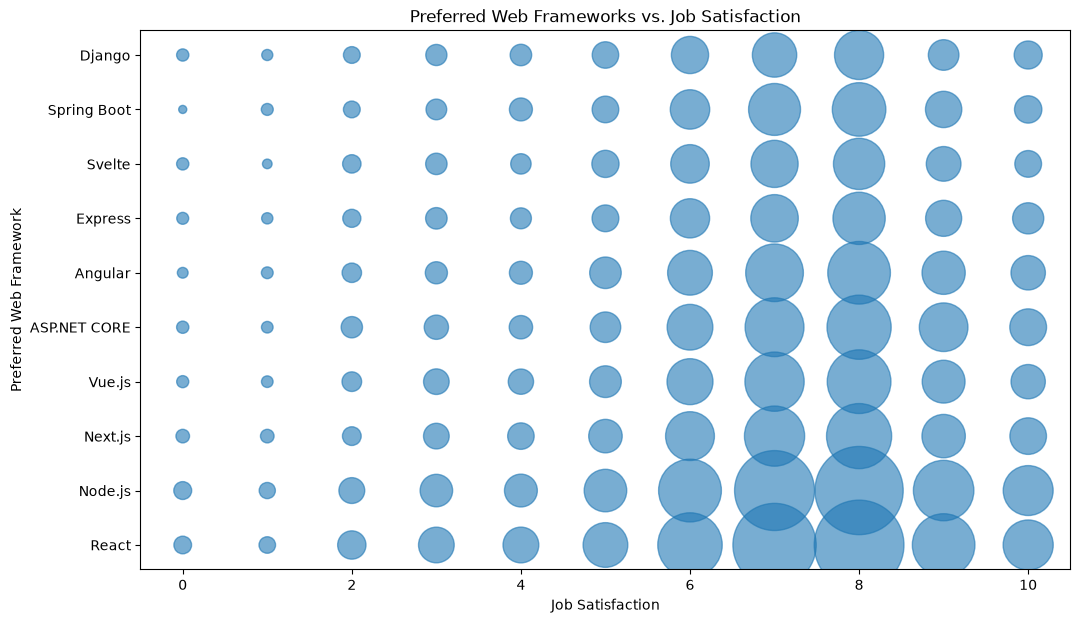

In [12]:
##Write your code here
# Get the top 10 preferred web frameworks
frameworks = (
    df["WebframeWantToWorkWith"]
    .dropna()
    .str.split(";")
    .explode()
)

top_frameworks = frameworks.value_counts().head(10).index

# Create bubble data
bubble_data = []

for framework in top_frameworks:
    mask = df["WebframeWantToWorkWith"].fillna("").str.contains(
        framework, regex=False
    )

    jobsat = pd.to_numeric(df["JobSat"], errors="coerce")

    for sat in sorted(jobsat.dropna().unique()):
        count = mask & (jobsat == sat)

        bubble_data.append({
            "Framework": framework,
            "JobSat": sat,
            "Frequency": count.sum()
        })

bubble_df = pd.DataFrame(bubble_data)

# Remove zero-frequency combinations
bubble_df = bubble_df[bubble_df["Frequency"] > 0]

# Create bubble plot
plt.figure(figsize=(12, 7))

plt.scatter(
    bubble_df["JobSat"],
    bubble_df["Framework"],
    s=bubble_df["Frequency"] * 2,
    alpha=0.6
)

plt.title("Preferred Web Frameworks vs. Job Satisfaction")
plt.xlabel("Job Satisfaction")
plt.ylabel("Preferred Web Framework")

plt.show()

#### 2. Bubble Plot for Admired Technologies Across Countries

- Visualize the distribution of admired technologies (`LanguageAdmired`) across different countries (`Country`).

- Use bubble size to represent the frequency of admiration.



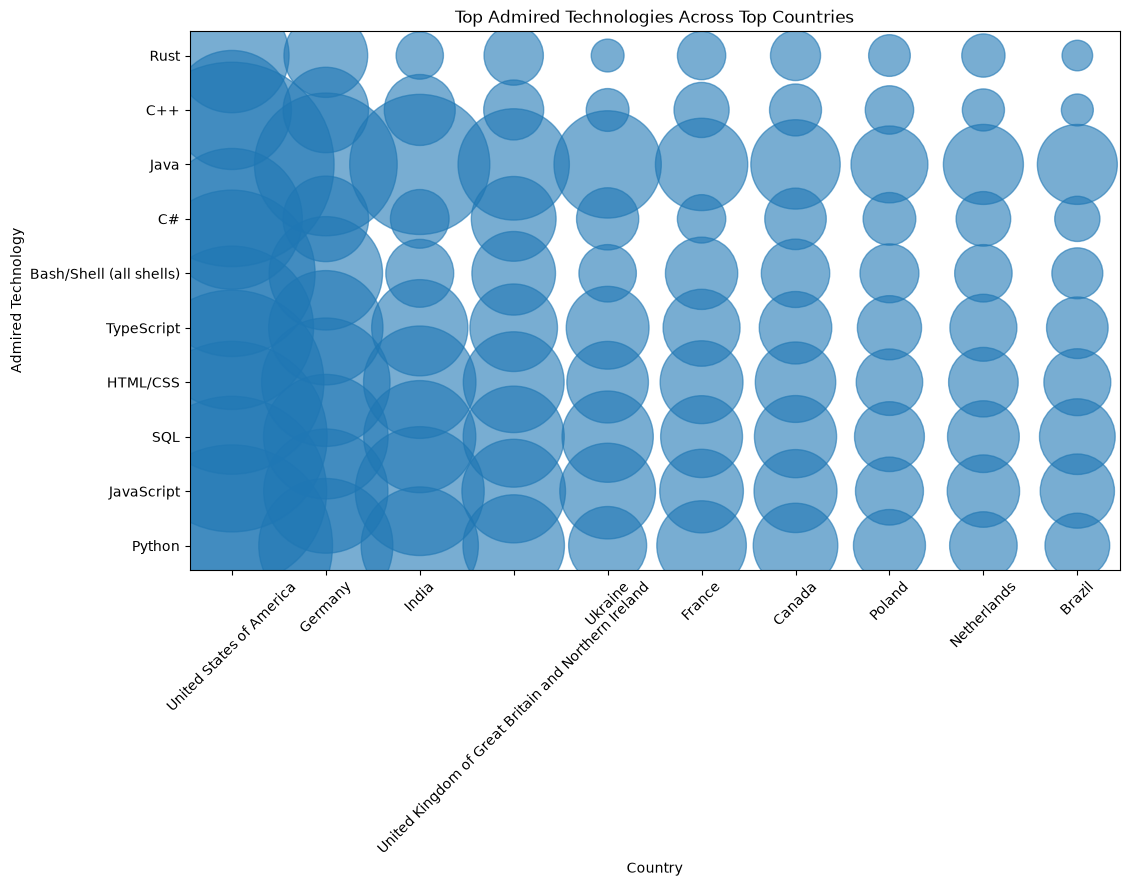

In [14]:
##Write your code here
# Get top 10 countries
top_countries = df["Country"].value_counts().head(10).index

# Filter to top countries
country_df = df[df["Country"].isin(top_countries)].copy()

# Get top 10 admired technologies
technologies = (
    country_df["LanguageAdmired"]
    .dropna()
    .str.split(";")
    .explode()
)

top_technologies = technologies.value_counts().head(10).index

# Create bubble data
bubble_data = []

for technology in top_technologies:
    mask = country_df["LanguageAdmired"].fillna("").str.contains(
        technology, regex=False
    )

    for country in top_countries:
        count = mask & (country_df["Country"] == country)

        if count.sum() > 0:
            bubble_data.append({
                "Technology": technology,
                "Country": country,
                "Frequency": count.sum()
            })

bubble_df = pd.DataFrame(bubble_data)

# Create bubble plot
plt.figure(figsize=(12, 7))

plt.scatter(
    bubble_df["Country"],
    bubble_df["Technology"],
    s=bubble_df["Frequency"] * 5,
    alpha=0.6
)

plt.title("Top Admired Technologies Across Top Countries")
plt.xlabel("Country")
plt.ylabel("Admired Technology")
plt.xticks(rotation=45)

plt.show()

## Final Step: Review


After completing the lab, you will have extensively used bubble plots to gain insights into developer community preferences, demographics, compensation trends, and job satisfaction.


## Summary


After completing this lab, you will be able to:

- Create and interpret bubble plots to analyze relationships and compositions within datasets.

- Use bubble plots to explore developer preferences, compensation trends, and satisfaction levels.

- Apply bubble plots to visualize complex relationships involving multiple dimensions effectively.


## Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


<!--
## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|
|2024-10-29|1.2|Madhusudhan Moole|Updated lab|
|2024-10-16|1.1|Madhusudhan Moole|Updated lab|
|2024-10-15|1.0|Raghul Ramesh|Created lab|
--!>


Copyright © IBM Corporation. All rights reserved.
